# Nivel 2: Base + Extras frente a Base

¿Cuánto mejora la predicción si el usuario trae una analítica más completa?, y ¿qué modelo lo aprovecha mejor?

| Modelo | Variables | Papel |
|---|---|---|
| Cox de Base | Base (19) | Listón a superar: es el modelo del nivel 1 |
| Cox | Base + Extras (35) | Compite |
| Cox elastic net | Base + Extras (35) | Compite |
| Random survival forest | Base + Extras (35) | Compite |
| Gradient boosting (XGBoost) | Base + Extras (35) | Compite |

Listones fijados antes de ver los resultados:

- **Quitar una variable de Extras:** vale si baja como mucho **0,002** el C-index misma edad.
- **Cox o XGBoost:** se queda Cox salvo que XGBoost optimizado gane al menos **0,02** en C-index misma edad.
- **Quedarse con el nivel 2:** el intervalo del bootstrap frente al Cox de Base no incluye el 0 y sobreviven varias variables de Extras.

Primero con valores fijos y, después, optimizando solo XGBoost: en el nivel 1, el elastic net optimizado quedó igual que Cox. Sin pesos muestrales. Todo con validación cruzada dentro de train: **el test no se toca**.

Notebook de trabajo: importa de `src/`. Tiempo aproximado, si se ejecuta entero: **más de una hora**.

In [1]:
# Imports
import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from src.config.model_sets import BASE
from src.config.paths import GOLD_TABLE
from src.config.study import COMPARISON_SEED
from src.models.s1_split import cv_folds, split_data
from src.models.s5_evaluation import compare_risks, evaluate_level, plot_calibration, tune_model
from src.utils.notebook_helpers import cox_weights, without

C:\Data\1_MisCosas\Evolve\TFM\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Datos

Mismo reparto que en el nivel 1: 80/20 con 5 bloques dentro de train.

In [2]:
# Extras at the start of this notebook; its final version is EXTRAS in model_sets.py
INITIAL_EXTRAS = [
    "triglycerides", "ggt", "alkaline_phosphatase", "bilirubin", "iron",
    "total_protein", "albumin", "hba1c", "crp", "vitamin_d",
    "chloride", "phosphorus", "ldh", "urine_acr",
    "systolic_bp", "diastolic_bp",
]
LEVEL_2 = BASE + INITIAL_EXTRAS

gold = pd.read_parquet(GOLD_TABLE)
train, test, folds = split_data(gold)

          people       deaths      
part        test train   test train
cycle                              
1999_2000    829  3316    212   846
2001_2002    925  3697    188   750
2003_2004    877  3511    165   661
2005_2006    874  3497    120   479
2007_2008   1043  4170    136   544
2009_2010   1120  4479     99   396
2011_2012    993  3968     70   278
2013_2014   1061  4248     51   206
2015_2016   1011  4043     31   122
2017_2018    966  3867     14    57
train: 38796 people, 4339 deaths
test:  9699 people, 1086 deaths
folds: [7760, 7759, 7759, 7759, 7759] people in each validation part


## 2. Cobertura de los Extras

Porcentaje de personas de train con el dato real, en total y por ciclo. El resto se rellena con la mediana de su sexo y grupo de edad, lo que diluye el efecto de la variable. Por eso, una variable con poco dato y sin efecto claro no significa lo mismo que una con casi todos sus datos y sin efecto.

In [3]:
has_value = train[INITIAL_EXTRAS].notna()
coverage = has_value.mean()

coverage_table = has_value.groupby(train["cycle"], observed=True).mean().T
coverage_table.insert(0, "total", coverage)
(coverage_table * 100).round(0).astype(int).sort_values("total")

cycle,total,1999_2000,2001_2002,2003_2004,2005_2006,2007_2008,2009_2010,2011_2012,2013_2014,2015_2016,2017_2018
triglycerides,54,66,66,65,48,48,49,50,49,47,55
crp,78,99,99,99,99,99,99,0,0,99,98
vitamin_d,89,0,97,99,99,86,99,99,99,100,99
systolic_bp,96,97,95,95,96,96,96,96,97,97,95
diastolic_bp,96,96,95,94,95,96,96,96,97,97,95
ggt,98,98,98,98,99,99,99,97,99,99,98
alkaline_phosphatase,98,98,98,98,99,99,99,97,99,99,98
bilirubin,98,98,98,98,99,99,98,97,99,99,98
iron,98,98,98,98,99,99,98,97,99,99,98
total_protein,98,98,98,98,99,99,98,97,99,99,98


## 3. Entrenar y evaluar

Cada persona se evalúa con un modelo entrenado sin ella. Casi todo el tiempo se va en el random survival forest.

In [4]:
reference_summary, reference_details = evaluate_level(BASE, train, folds, models=["cox"])
level_summary, level_details = evaluate_level(LEVEL_2, train, folds)

## 4. Resumen

| Columna | Qué mide | Mejor |
|---|---|---|
| `c_index` | De dos personas, cuántas veces da más riesgo a la que muere antes en 10 años | Alto |
| `c_index_std` | Cuánto varía entre los 5 bloques | Bajo |
| `c_index_fit` | Lo mismo con personas ya vistas; muy por encima de `c_index` = sobreajuste | Cerca de `c_index` |
| `c_index_same_age` | Lo mismo, dentro de cada grupo de edad: **lo que más importa para el producto** | Alto |
| `c_index_female`, `c_index_male` | Lo mismo, por sexo | Altos y parecidos |
| `calibration_gap` | Diferencia media entre el riesgo previsto y el observado | Bajo |
| `worst_underestimate` | Grupo donde más se queda corto el riesgo previsto; es el error peor | Bajo |
| `seconds_per_fit` | Tiempo de un entrenamiento | Bajo |

In [5]:
pd.concat([reference_summary.rename(index={"cox": "cox_base"}), level_summary])

,c_index,c_index_std,c_index_fit,c_index_same_age,c_index_female,c_index_male,calibration_gap,worst_underestimate,seconds_per_fit
cox_base,0.8476,0.0064,0.8480,0.7034,0.8513,0.8400,0.0042,0.0139,4.0068
cox,0.8586,0.0050,0.8597,0.7306,0.8633,0.8506,0.0053,0.0209,5.7146
elastic_net,0.8583,0.0050,0.8594,0.7306,0.8631,0.8505,0.0063,0.0259,2.7784
random_forest,0.8530,0.0032,0.9392,0.7160,0.8562,0.8471,0.0164,0.0699,153.0650
gradient_boosting,0.8577,0.0043,0.8781,0.7271,0.8608,0.8505,0.0031,0.0040,2.1991


## 5. Por grupo de edad

¿Distingue a personas de la misma edad en todos los grupos? Los grupos con pocas muertes son menos fiables.

In [6]:
by_age = pd.DataFrame({name: detail["by_age"]["c_index"] for name, detail in level_details.items()})
by_age.insert(0, "cox_base", reference_details["cox"]["by_age"]["c_index"])
by_age["deaths"] = reference_details["cox"]["by_age"]["deaths"].astype(int)
by_age.round(3)

,cox_base,cox,elastic_net,random_forest,gradient_boosting,deaths
18-29,0.682,0.715,0.711,0.663,0.708,81
30-39,0.714,0.719,0.717,0.705,0.711,89
40-49,0.704,0.748,0.749,0.748,0.733,217
50-59,0.735,0.764,0.764,0.736,0.762,388
60-69,0.720,0.746,0.746,0.736,0.746,828
70-79,0.683,0.709,0.709,0.695,0.705,1246


## 6. Calibración

Una gráfica por modelo. Sobre la diagonal, el riesgo previsto coincide con el observado; por encima de ella, el modelo se queda corto.

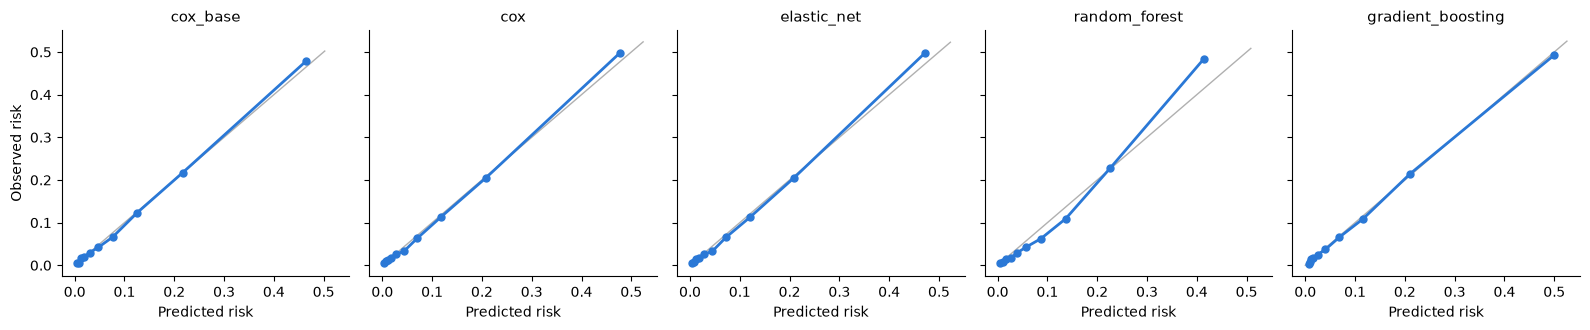

In [7]:
plot_calibration({"cox_base": reference_details["cox"], **level_details});

In [8]:
pd.DataFrame({name: detail["calibration"]["gap"] for name, detail in level_details.items()}).round(3)

,cox,elastic_net,random_forest,gradient_boosting
0,0.000,0.000,0.002,-0.003
1,0.002,0.001,-0.002,-0.000
2,0.003,0.003,-0.003,0.002
3,0.001,0.000,-0.010,0.001
4,-0.001,-0.002,-0.010,0.000
5,-0.010,-0.012,-0.015,-0.003
6,-0.007,-0.007,-0.024,-0.003
7,-0.004,-0.008,-0.027,-0.007
8,-0.003,-0.004,0.002,0.004
9,0.021,0.026,0.070,-0.007


## 7. ¿Los Extras aportan de verdad?

Comparación con bootstrap del Cox de Base + Extras frente al Cox de Base, de unos 22 minutos. La mejora es real si el intervalo (`low`, `high`) no incluye el 0.

In [9]:
compare_risks(level_details["cox"]["risk"], reference_details["cox"]["risk"], train)

,difference,low,high
c_index,0.0109,0.0090,0.0129
c_index_same_age,0.0269,0.0219,0.0328


## 8. Optimizar XGBoost

50 intentos, buscando el mejor C-index misma edad en los mismos bloques de antes.

In [10]:
tuned = {"gradient_boosting": tune_model("gradient_boosting", LEVEL_2, train, folds)}
tuned

{'gradient_boosting': {'n_estimators': 554,
  'learning_rate': 0.01989248900224276,
  'max_depth': 5,
  'min_child_weight': 21,
  'subsample': 0.5289319965877107,
  'colsample_bytree': 0.9742702898822766,
  'reg_lambda': 0.02889181505230819}}

## 9. Comparar Cox y XGBoost optimizado

Con bloques nuevos, para que la optimización no infle el resultado. `xgboost_advantage` es lo que gana XGBoost en C-index misma edad; el listón es **0,02**.

In [11]:
comparison_folds = cv_folds(train, seed=COMPARISON_SEED)
tuned_summary, tuned_details = evaluate_level(LEVEL_2, train, comparison_folds, models=["cox", "gradient_boosting"], settings=tuned)
xgboost_advantage = tuned_summary.loc["gradient_boosting", "c_index_same_age"] - tuned_summary.loc["cox", "c_index_same_age"]
print(f"xgboost_advantage: {xgboost_advantage:.4f}")
tuned_summary

xgboost_advantage: 0.0021


,c_index,c_index_std,c_index_fit,c_index_same_age,c_index_female,c_index_male,calibration_gap,worst_underestimate,seconds_per_fit
cox,0.8585,0.0027,0.8597,0.7301,0.8631,0.8506,0.0051,0.0190,7.1756
gradient_boosting,0.8611,0.0020,0.8924,0.7322,0.8641,0.8538,0.0056,0.0065,7.6534


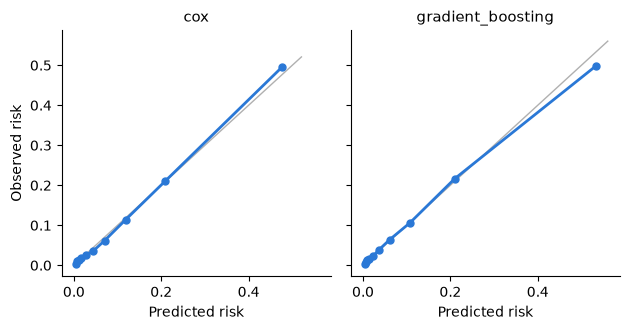

In [12]:
plot_calibration(tuned_details);

## 10. Peso de cada variable en Cox

Cox simple ajustado con todo train, sin validación: describe el modelo, no mide su acierto.

- **`hazard_ratio`:** por cuánto se multiplica el riesgo al subir la variable una desviación estándar, a igualdad de las demás. Por encima de 1, suma riesgo; por debajo, resta.
- **`low`, `high`:** su intervalo de confianza del 95 %. Si incluye el 1, el efecto no se distingue de cero (`clear` = False).
- **`coverage`:** parte de las personas con el dato real, solo en Extras.

In [13]:
weights = cox_weights(LEVEL_2, train)
weights["coverage"] = coverage.reindex(weights.index)
weights.sort_values("p").round(3)

,hazard_ratio,low,high,p,clear,coverage
covariate,,,,,,
age,3.250,3.081,3.428,0.000,True,NaN
rdw,1.253,1.215,1.293,0.000,True,NaN
urine_acr,1.166,1.138,1.195,0.000,True,0.987
alt,0.719,0.678,0.762,0.000,True,NaN
erythrocytes,0.707,0.664,0.752,0.000,True,NaN
sex_male,1.552,1.429,1.686,0.000,True,NaN
albumin,0.824,0.792,0.857,0.000,True,0.984
ggt,1.194,1.152,1.238,0.000,True,0.984
hemoglobin,1.395,1.301,1.495,0.000,True,NaN


## 11. Variantes

Mismo Cox y mismos bloques, cambiando solo las variables. Solo se pueden quitar variables de Extras: Base ya se decidió en el nivel 1 y es lo que usa quien solo trae la analítica básica. Una variante vale si baja como mucho **0,002** el C-index misma edad frente a las 35.

| Variante | Qué cambia |
|---|---|
| `base_19` | Sin Extras, como referencia |
| `all_35` | Base + todos los Extras |
| `no_unclear` | Quita los Extras sin efecto claro |
| `keep_low_coverage` | Igual, pero deja los que tienen menos de un 80 % de cobertura, cuyo efecto puede estar diluido |

In [14]:
LOW_COVERAGE = 0.8

unclear = [column for column in INITIAL_EXTRAS if not weights.loc[column, "clear"]]
unclear_well_covered = [column for column in unclear if coverage[column] >= LOW_COVERAGE]

variants = {
    "base_19": BASE,
    "all_35": LEVEL_2,
    "no_unclear": without(LEVEL_2, unclear),
    "keep_low_coverage": without(LEVEL_2, unclear_well_covered),
}
print("Extras without a clear effect:", unclear)

variant_summary = pd.concat(
    {name: evaluate_level(columns, train, folds, models=["cox"])[0].iloc[0] for name, columns in variants.items()}, axis=1
).T
variant_summary.insert(0, "variables", [len(columns) for columns in variants.values()])
variant_summary["same_age_change"] = variant_summary["c_index_same_age"] - variant_summary.loc["all_35", "c_index_same_age"]
variant_summary[["variables", "c_index", "c_index_same_age", "same_age_change", "calibration_gap", "worst_underestimate"]]

Extras without a clear effect: ['triglycerides', 'bilirubin', 'iron', 'total_protein', 'hba1c', 'crp']


,variables,c_index,c_index_same_age,same_age_change,calibration_gap,worst_underestimate
base_19,19,0.8476,0.7034,-0.0272,0.0042,0.0139
all_35,35,0.8586,0.7306,0.0000,0.0053,0.0209
no_unclear,29,0.8587,0.7310,0.0004,0.0049,0.0182
keep_low_coverage,31,0.8586,0.7308,0.0002,0.0049,0.0194


In [15]:
cox_weights(variants["no_unclear"], train).sort_values("p").round(3)

,hazard_ratio,low,high,p,clear,coverage
covariate,,,,,,
age,3.250,3.084,3.425,0.000,True,NaN
rdw,1.254,1.216,1.294,0.000,True,NaN
urine_acr,1.171,1.143,1.199,0.000,True,0.987
alt,0.717,0.676,0.760,0.000,True,NaN
erythrocytes,0.711,0.670,0.755,0.000,True,NaN
albumin,0.826,0.797,0.855,0.000,True,0.984
sex_male,1.534,1.414,1.665,0.000,True,NaN
ggt,1.202,1.161,1.245,0.000,True,0.984
hemoglobin,1.376,1.289,1.468,0.000,True,NaN


## 12. Conclusión

**Modelo del nivel 2: Cox simple con 29 variables**, las 19 de Base y 10 de Extras. Las cifras son de validación cruzada dentro de train; el test sigue sin tocar.

### Qué se hizo y por qué

**1. Mirar la cobertura de los Extras**

Casi todos tienen dato en el 96-100 % de las personas. Las excepciones son los triglicéridos (54 %, solo el subgrupo en ayunas), la PCR (78 %, sin 2011-2014) y la vitamina D (89 %, sin 1999-2000).

**2. Comparar los cuatro modelos con valores fijos y las 35 variables**

| Modelo | C-index | Misma edad | En entrenamiento |
|---|---|---|---|
| Cox de Base (nivel 1) | 0,848 | 0,703 | 0,848 |
| Cox | 0,859 | 0,731 | 0,860 |
| Elastic net | 0,858 | 0,731 | 0,859 |
| Random survival forest | 0,853 | 0,716 | 0,939 |
| XGBoost | 0,858 | 0,727 | 0,878 |

Cox y elastic net quedan delante, y otra vez son iguales. El random survival forest vuelve a sobreajustar y a quedarse 7 puntos corto en el grupo de mayor riesgo.

**3. Confirmar que los Extras aportan de verdad**

Cox de Base + Extras frente a Cox de Base, con bootstrap: **+0,011** de C-index global (intervalo del 95 %: 0,009 a 0,013) y **+0,027** en misma edad (0,022 a 0,033). La mejora es real: unas 3 parejas más de cada 100 entre personas de edad parecida. Mejora en todos los grupos de edad; en el de 30-39, apenas.

**4. Optimizar XGBoost y compararlo con Cox, con otros bloques**

| Modelo | C-index | Misma edad | En entrenamiento | Mayor infraestimación |
|---|---|---|---|---|
| Cox simple | 0,859 | 0,730 | 0,860 | 1,9 puntos |
| XGBoost optimizado | 0,861 | 0,732 | 0,892 | 0,7 puntos |

XGBoost gana 0,002 en misma edad, muy lejos del listón de 0,02, y sobreajusta más. Se queda Cox.

**5. Quitar los Extras que no aportan**

Seis Extras no tienen efecto claro: triglicéridos, PCR, bilirrubina, hierro, proteínas totales y HbA1c. Al quitarlos, el C-index misma edad no baja (0,7306 → 0,7310). Dejar los dos con poca cobertura, triglicéridos y PCR, tampoco suma (0,7308): la cobertura no explica su falta de efecto. Salen los seis.

### Resultado final

| Cox simple, 29 variables | |
|---|---|
| C-index | 0,859 |
| C-index misma edad | 0,731 |
| Diferencia media de calibración | 0,5 puntos |
| Mayor infraestimación | 1,8 puntos |

**Variables:** las 19 de Base, más cociente albúmina/creatinina en orina, albúmina, GGT, vitamina D, LDH, cloro, fósforo, fosfatasa alcalina, sistólica y diastólica.

### Limitaciones

- **Más infraestimación en el grupo de mayor riesgo:** 1,8 puntos, frente a 1,4 del Cox de Base y 0,7 de XGBoost optimizado. Es el error peor; hay que vigilarlo al traducir el riesgo a edad.
- **Variables de Base que pierden fuerza:** con los Extras, creatinina, urea y sodio dejan de tener un efecto claro, posiblemente porque el cociente en orina y el cloro recogen parte de lo mismo. Se quedan porque Base tiene que funcionar sola.
- **Signos difíciles de leer:** la diastólica resta y la sistólica suma; juntas describen la presión de pulso. Hemoglobina y ALT siguen como en el nivel 1.
- **PCR y triglicéridos no se usan,** aunque son de los más pedidos. La app tendrá que aclararlo.
- **Es el mejor caso:** en NHANES casi todos los Extras tienen dato, y el usuario real traerá solo algunos; el resto se imputará. Cuánto se pierde va con el mínimo viable de variables.
- **Sin pesos muestrales** y con población de EE. UU.; se asume equivalencia con España.
- **Falta el test,** que se mira una sola vez, al final.